# First look at the data

PM2.5 from the US Embassy station + weather + CAMS, hourly, since Sep 2020.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config import EMBASSY_END, FIGURES_DIR
from features import load_hourly, make_daily

plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
df = load_hourly()
df = df[df.time < EMBASSY_END]
df.shape

(45624, 11)

In [3]:
df.head()

,time,pm25,temp,humidity,wind,wind_dir,pressure,precipitation,blh,cams_pm25,cams_pm10
0,2020-09-01 00:00:00,19.0,20.9,65.0,6.6,209.0,920.3,0.5,25.0,NaN,NaN
1,2020-09-01 01:00:00,15.0,20.2,61.0,7.1,246.0,920.6,0.0,25.0,NaN,NaN
2,2020-09-01 02:00:00,NaN,19.0,65.0,7.0,215.0,920.3,0.0,25.0,NaN,NaN
3,2020-09-01 03:00:00,6.0,18.9,65.0,6.4,207.0,920.1,0.0,40.0,NaN,NaN
4,2020-09-01 04:00:00,NaN,18.1,68.0,7.9,227.0,920.3,0.0,30.0,NaN,NaN


In [4]:
df.describe().round(1)

,time,pm25,temp,humidity,wind,wind_dir,pressure,precipitation,blh,cams_pm25,cams_pm10
count,45624,35261.0,45624.0,45624.0,45624.0,45624.0,45624.0,45624.0,41256.0,28771.0,28771.0
mean,2023-04-09 11:30:00,30.9,11.2,55.7,5.6,180.4,924.3,0.1,263.2,22.8,34.2
min,2020-09-01 00:00:00,0.0,-28.4,7.0,0.0,1.0,905.7,0.0,10.0,0.4,0.6
25%,2021-12-20 05:45:00,9.0,1.7,38.0,3.3,96.0,919.8,0.0,25.0,13.1,19.6
50%,2023-04-09 11:30:00,16.0,11.8,54.0,5.1,167.0,923.8,0.0,55.0,18.6,28.6
75%,2024-07-27 17:15:00,33.0,20.8,73.0,7.2,274.0,928.3,0.0,285.0,28.3,42.4
max,2025-11-14 23:00:00,421.0,39.1,100.0,38.6,360.0,949.3,10.6,3935.0,153.7,347.4
std,NaN,38.8,12.0,21.6,3.3,107.6,6.1,0.3,439.2,14.4,22.0


In [5]:
# how much PM2.5 is missing each year
(df.pm25.isna().groupby(df.time.dt.year).mean() * 100).round(1)

time
2020    24.5
2021    41.7
2022    46.1
2023    16.3
2024     5.4
2025     0.7
Name: pm25, dtype: float64

In [6]:
df["month"] = df.time.dt.month
df["hour"] = df.time.dt.hour
df["dayofweek"] = df.time.dt.dayofweek
df["season"] = df.month.map(lambda m: "winter" if m in (12, 1, 2) else "summer" if m in (6, 7, 8) else "other")

## PM2.5 by month

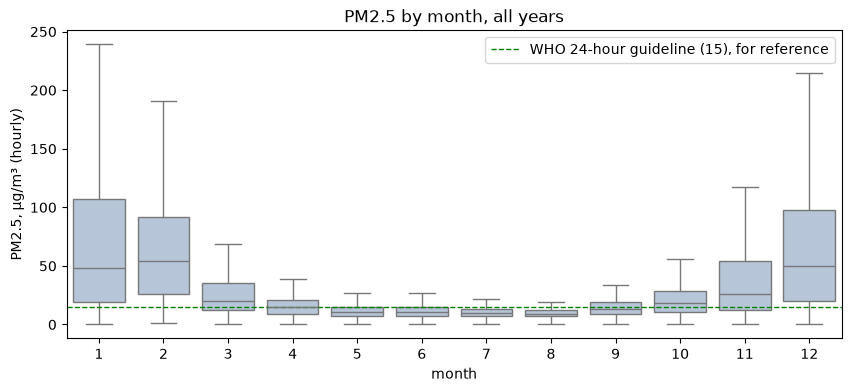

In [7]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="month", y="pm25", showfliers=False, color="lightsteelblue", ax=ax)
ax.axhline(15, color="green", linestyle="--", linewidth=1, label="WHO 24-hour guideline (15), for reference")
ax.set_ylabel("PM2.5, µg/m³ (hourly)")
ax.set_title("PM2.5 by month, all years")
ax.legend()
fig.savefig(FIGURES_DIR / "pm25_by_month.png", dpi=120, bbox_inches="tight")

dec-feb are the worst summer is mostly under the who line

In [8]:
monthly = df.groupby("month").pm25.mean()
print(monthly.round(1))
print("winter / summer:", round(monthly[[12, 1, 2]].mean() / monthly[[6, 7, 8]].mean(), 1))

month
1     70.0
2     62.2
3     26.0
4     16.6
5     11.8
6     12.0
7     10.7
8     10.1
9     14.7
10    21.8
11    38.2
12    67.0
Name: pm25, dtype: float64
winter / summer: 6.1


## Hour of the day, winter vs summer

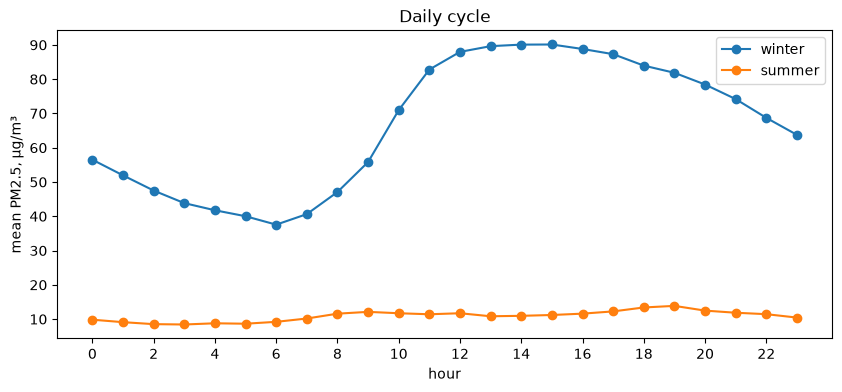

In [9]:
fig, ax = plt.subplots()
for season in ["winter", "summer"]:
    part = df[df.season == season]
    part.groupby("hour").pm25.mean().plot(ax=ax, marker="o", label=season)
ax.set_xticks(range(0, 24, 2))
ax.set_ylabel("mean PM2.5, µg/m³")
ax.set_title("Daily cycle")
ax.legend()
fig.savefig(FIGURES_DIR / "daily_cycle.png", dpi=120, bbox_inches="tight")

winter peak is at 15:00 not evening like i thought

## Weekdays vs weekends
If traffic matters a lot, weekends should be cleaner.

In [10]:
heating = df[df.month.isin([11, 12, 1, 2, 3])]
heating.groupby("dayofweek").pm25.mean().round(1)

dayofweek
0    53.5
1    51.4
2    52.2
3    52.0
4    55.0
5    52.2
6    50.2
Name: pm25, dtype: float64

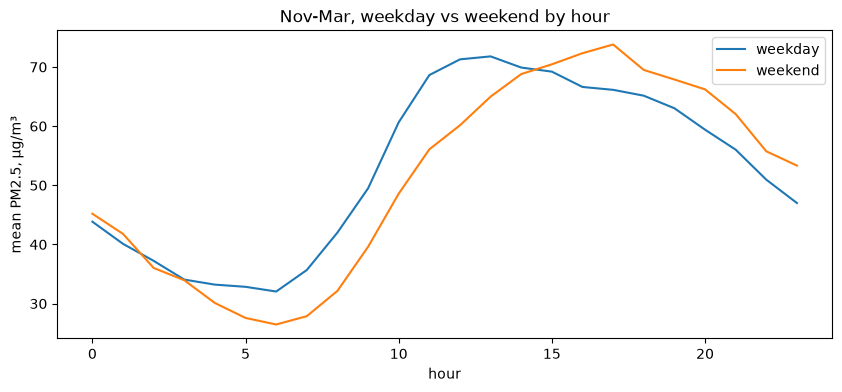

In [11]:
fig, ax = plt.subplots()
heating.assign(weekend=heating.dayofweek >= 5).groupby(["hour", "weekend"]).pm25.mean().unstack().plot(ax=ax)
ax.set_title("Nov-Mar, weekday vs weekend by hour")
ax.set_ylabel("mean PM2.5, µg/m³")
ax.legend(["weekday", "weekend"])

weekends almost same as weekdays so probably not traffic

## Top 10 dirtiest days

In [12]:
daily = make_daily(df)
daily.sort_values("pm25", ascending=False).head(10)[
    ["date", "pm25", "pm25_max", "temp", "wind", "blh", "blh_night", "pm25_hours"]
].set_index("date").round(1)

,pm25,pm25_max,temp,wind,blh,blh_night,pm25_hours
date,,,,,,,
2020-12-24,222.0,337.0,-9.8,8.5,34.2,24.6,24
2020-12-25,204.1,277.0,-5.6,7.6,29.0,22.1,23
2023-01-16,204.1,342.0,-13.8,9.3,24.0,22.1,18
2021-01-29,195.5,258.0,-6.7,7.3,29.0,20.0,24
2020-12-18,185.1,284.0,-6.4,3.6,26.5,20.0,24
2020-12-28,183.3,229.0,-9.3,10.4,33.5,24.6,23
2021-01-09,180.2,396.0,-10.1,3.6,58.3,23.8,24
2023-01-28,177.0,272.0,-8.0,9.1,28.3,25.4,24
2021-01-08,170.0,224.0,-11.3,4.9,71.9,33.3,24


## Weather and smog

Text(0.5, 0.98, 'Nov-Mar days')

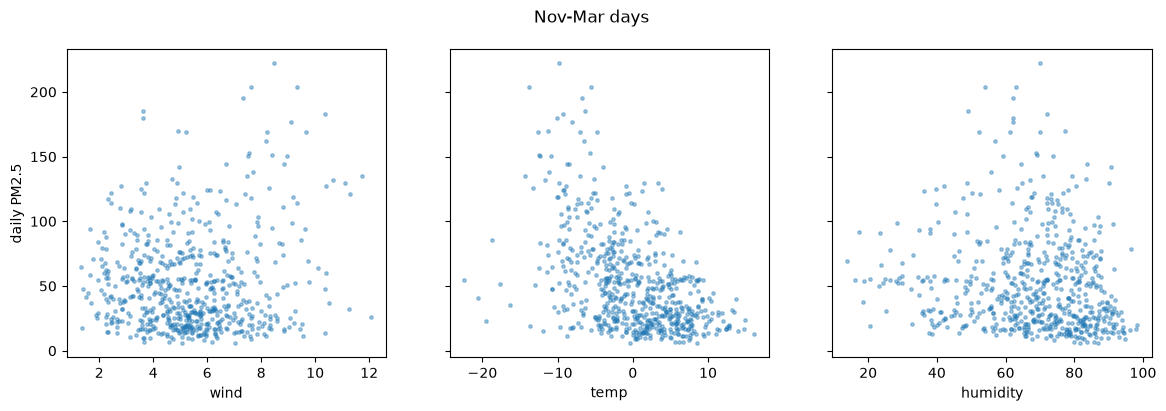

In [13]:
winter_days = daily[daily.date.dt.month.isin([11, 12, 1, 2, 3])]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, col in zip(axes, ["wind", "temp", "humidity"]):
    ax.scatter(winter_days[col], winter_days.pm25, s=6, alpha=0.4)
    ax.set_xlabel(col)
axes[0].set_ylabel("daily PM2.5")
fig.suptitle("Nov-Mar days")

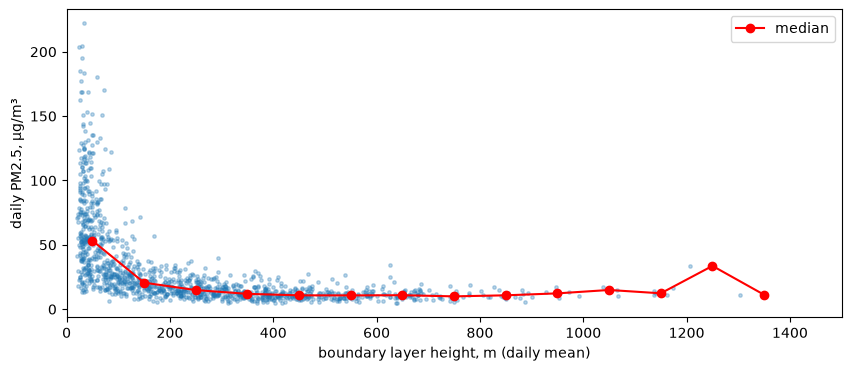

In [14]:
# boundary layer height = how high the air can mix. low = inversion
fig, ax = plt.subplots()
ax.scatter(daily.blh, daily.pm25, s=6, alpha=0.3)
bins = pd.cut(daily.blh, bins=np.arange(0, 1600, 100))
med = daily.groupby(bins, observed=True).pm25.median()
ax.plot([b.mid for b in med.index], med.values, color="red", marker="o", label="median")
ax.set_xlabel("boundary layer height, m (daily mean)")
ax.set_ylabel("daily PM2.5, µg/m³")
ax.set_xlim(0, 1500)
ax.legend()
fig.savefig(FIGURES_DIR / "pm25_vs_blh.png", dpi=120, bbox_inches="tight")

low blh = way more pm2.5 the air just cant mix

<Axes: >

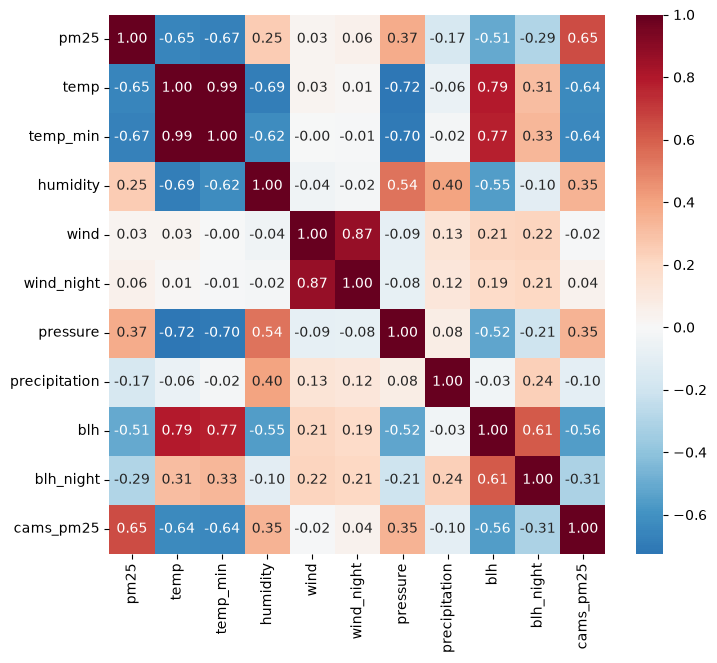

In [15]:
cols = ["pm25", "temp", "temp_min", "humidity", "wind", "wind_night", "pressure",
        "precipitation", "blh", "blh_night", "cams_pm25"]
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(daily[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)

## Heating season (about 15 Oct - 15 Apr)

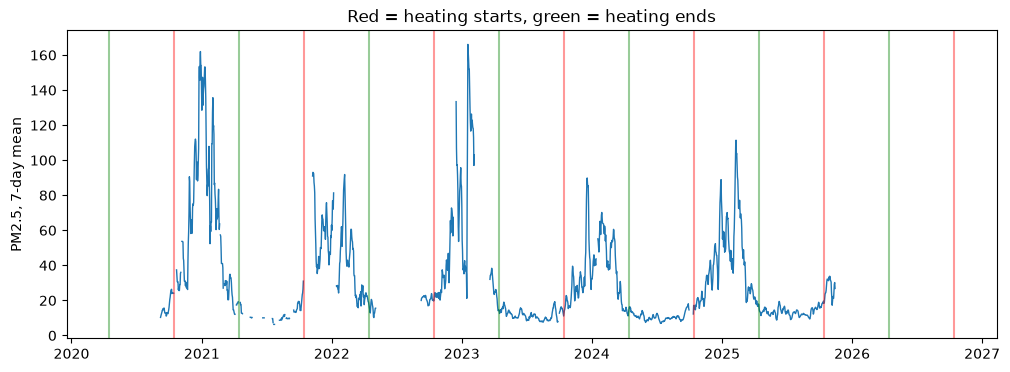

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.date, daily.pm25.rolling(7, min_periods=3).mean(), linewidth=1)
for year in range(2020, 2027):
    ax.axvline(pd.Timestamp(f"{year}-10-15"), color="red", alpha=0.4)
    ax.axvline(pd.Timestamp(f"{year}-04-15"), color="green", alpha=0.4)
ax.set_ylabel("PM2.5, 7-day mean")
ax.set_title("Red = heating starts, green = heating ends")
fig.savefig(FIGURES_DIR / "timeline_heating.png", dpi=120, bbox_inches="tight")

In [17]:
# 2 weeks before vs 2 weeks after the start of heating, each year
rows = []
for year in range(2020, 2027):
    start = pd.Timestamp(f"{year}-10-15")
    before = daily[(daily.date >= start - pd.Timedelta(days=14)) & (daily.date < start)].pm25.mean()
    after = daily[(daily.date >= start) & (daily.date < start + pd.Timedelta(days=14))].pm25.mean()
    rows.append({"year": year, "before": before, "after": after})
pd.DataFrame(rows).round(1)

,year,before,after
0,2020,25.2,30.9
1,2021,19.7,NaN
2,2022,21.3,22.7
3,2023,13.7,19.7
4,2024,17.2,17.9
5,2025,17.7,30.9
6,2026,NaN,NaN


## How wrong is CAMS?

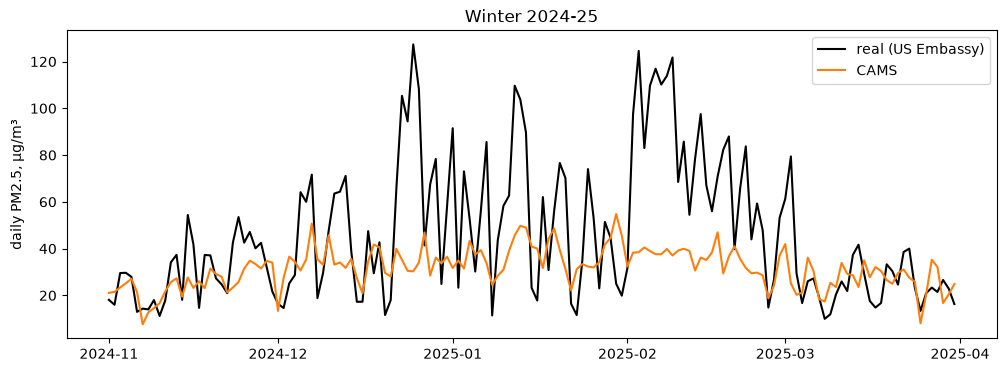

In [18]:
w = daily[(daily.date >= "2024-11-01") & (daily.date < "2025-04-01")]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w.date, w.pm25, label="real (US Embassy)", color="black")
ax.plot(w.date, w.cams_pm25, label="CAMS", color="tab:orange")
ax.set_ylabel("daily PM2.5, µg/m³")
ax.set_title("Winter 2024-25")
ax.legend()
fig.savefig(FIGURES_DIR / "cams_vs_real.png", dpi=120, bbox_inches="tight")

cams is mostly under the real line in winter and misses the worst days

In [19]:
both = daily.dropna(subset=["pm25", "cams_pm25"]).copy()
both["season"] = both.date.dt.month.map(lambda m: "winter" if m in (12, 1, 2) else "summer" if m in (6, 7, 8) else "other")
both["error"] = both.cams_pm25 - both.pm25
both.groupby("season").agg(
    days=("pm25", "size"),
    real_mean=("pm25", "mean"),
    cams_mean=("cams_pm25", "mean"),
    mae=("error", lambda e: e.abs().mean()),
    bias=("error", "mean"),
).round(1)

,days,real_mean,cams_mean,mae,bias
season,,,,,
other,571,20.3,20.9,6.9,0.6
summer,274,11.0,14.4,4.2,3.4
winter,223,60.9,34.3,32.4,-26.6


Text(0, 0.5, 'CAMS')

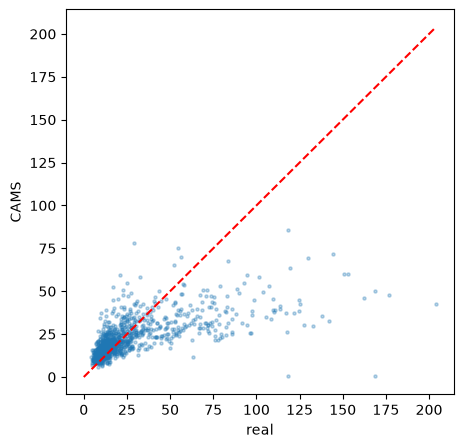

In [20]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(both.pm25, both.cams_pm25, s=5, alpha=0.3)
lim = both[["pm25", "cams_pm25"]].max().max()
ax.plot([0, lim], [0, lim], color="red", linestyle="--")
ax.set_xlabel("real")
ax.set_ylabel("CAMS")

## What I learned

- winter is like 6 times dirtier than summer
- i thought evening would be the worst but its 15:00
- cold and low blh matter way more than wind
- cams is too low in winter so theres room to do better